# `generate_voxel_image`

Generates a 3D voxelized image from an OpenPNM pore network, labeling solid voxels as `0`, pore voxels as `1`, and throat voxels as `2`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import openpnm as op

import porespy as ps

ps.visualization.set_mpl_style()

First, create a small 3D cubic pore network in OpenPNM with sphere-and-cylinder geometry:

In [2]:
def make_network(seed=0):
    np.random.seed(seed)
    pn = op.network.Cubic(shape=[4, 4, 4], spacing=1e-4)
    pn.add_model_collection(op.models.collections.geometry.spheres_and_cylinders)
    pn.regenerate_models()
    return pn

pn = make_network()
print(f"Pores: {pn.Np}, Throats: {pn.Nt}")

Pores: 64, Throats: 144


## `network` and `max_dim`

Passing `max_dim` fixes the resolution along the largest dimension of the network. In the returned array, `0` represents solid, `1` represents pores, and `2` represents throats.

Image shape: (100, 100, 100)
Unique labels (0=solid, 1=pore, 2=throat): [0 1 2]


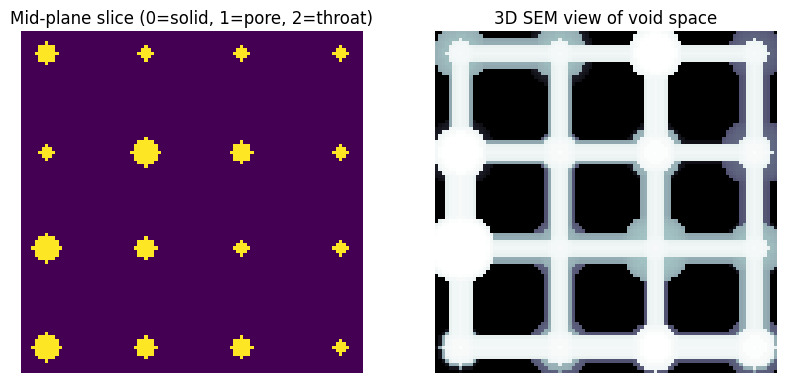

In [3]:
im_spheres = ps.networks.generate_voxel_image(
    network=make_network(),
    pore_shape="sphere",
    throat_shape="cylinder",
    max_dim=100,
)
print("Image shape:", im_spheres.shape)
print("Unique labels (0=solid, 1=pore, 2=throat):", np.unique(im_spheres))

fig, ax = plt.subplots(1, 2, figsize=[10, 4])
slice_idx = im_spheres.shape[2] // 2
ax[0].imshow(im_spheres[:, :, slice_idx], origin="lower", interpolation="none")
ax[0].set_title("Mid-plane slice (0=solid, 1=pore, 2=throat)")
ax[0].axis(False)
ax[1].imshow(ps.visualization.sem(im_spheres > 0), cmap=plt.cm.bone)
ax[1].set_title("3D SEM view of void space")
ax[1].axis(False);

## `pore_shape`

Setting `pore_shape='cube'` renders cubic pores instead of spherical pores:

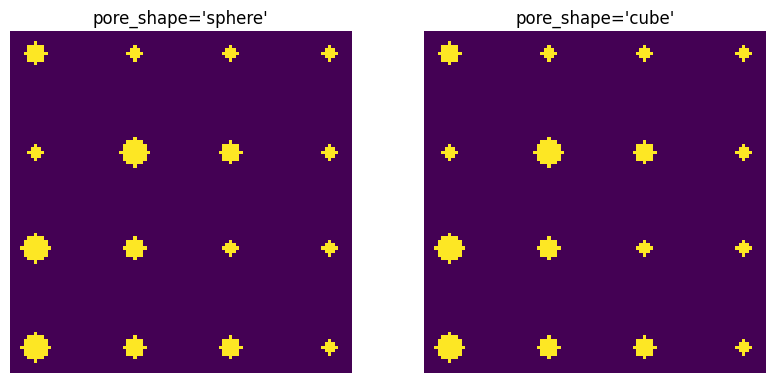

In [4]:
im_cubes = ps.networks.generate_voxel_image(
    network=make_network(),
    pore_shape="cube",
    throat_shape="cylinder",
    max_dim=100,
)

fig, ax = plt.subplots(1, 2, figsize=[10, 4])
ax[0].imshow(im_spheres[:, :, slice_idx], origin="lower", interpolation="none")
ax[0].set_title("pore_shape='sphere'")
ax[0].axis(False)
ax[1].imshow(im_cubes[:, :, slice_idx], origin="lower", interpolation="none")
ax[1].set_title("pore_shape='cube'")
ax[1].axis(False);